# Two bandaged cubes against the 3x3x3

| | bandage | in words |
|---|---|---|
| **A** | `F + FD \| FL + FLD \| L + LD` | three 1x1x2 blocks on the front-left of the bottom layer: F center glued to the DF edge, FL edge glued to the DLF corner, L center glued to the DL edge |
| **B** | `LDB + LD + LDF \| RDB + RD + RDF` | two 1x1x3 bars: the left and right columns of the bottom layer (DBL-DL-DLF and DRB-DR-DFR) |

Cubie names list the faces a piece touches, in any order (`FD` = `DF`, `LDB` = `DBL`).
`+` glues cubies into a block and `|` separates blocks. A turn is legal only if it cuts no block.
Moves are the 18 face turns (HTM).

The profiles were computed with a larger setup than the 100-puzzle study (20M-state table, 280
random positions, 1M-node search balls), and saved to `study/two_bandages.json`:

```python
rubik.difficulty(bandage, max_nodes=20_000_000, samples=280, ball_nodes=1_000_000, alg_time=30)
```

A  legal at start: R R2 R' L L2 L' U U2 U' F F2 F' B B2 B'
B  legal at start: R R2 R' L L2 L' U U2 U' D D2 D'


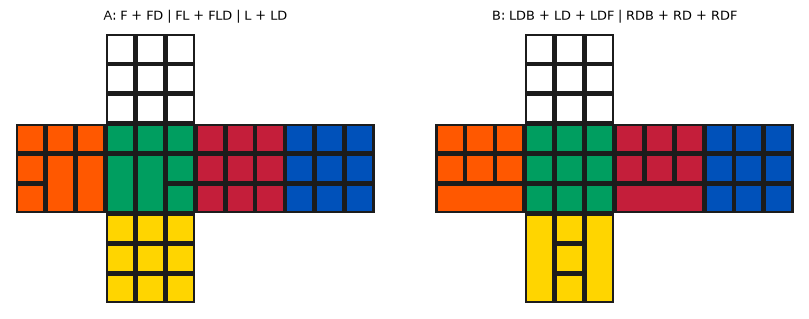

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rubik

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
two = json.load(open("../study/two_bandages.json", encoding="utf-8"))
study = json.load(open("../study/results.json", encoding="utf-8"))
base = next(r for r in study if r["id"] == "333")
A, B = two
rubik.plot_cubes([rubik.Cube(bandage=p["input"]) for p in two], titles=[f"{p['name']}: {p['input']}" for p in two], ncols=2, size=3.2)
for p in two:
    print(f"{p['name']}  legal at start: {' '.join(rubik.Cube(bandage=p['input']).legal_moves('htm'))}")

## KPIs side by side

* **states**: exact number of reachable positions.
* **God's number**: exact only for puzzles small enough to enumerate. Here it is a proven lower bound
  (`≥`) plus a counting estimate (`~`, which gives 18 on the 3x3x3, against the true 20).
* **mean solution**: average optimal solution of a random position. `≥` means some sampled positions
  were too deep to solve exactly, so the value is a lower bound.
* **legal turns**: average number of legal face turns in a random position.
* **algorithms**: shortest sequence for each effect that leaves everything else, blocks included,
  solved. "impossible" is exact: the puzzle's group contains no such effect.

In [2]:
KINDS = [("edge3", "edge 3-cycle"), ("corner3", "corner 3-cycle"), ("edge_flip", "2-edge flip"), ("corner_twist", "2-corner twist")]

def alg(p, k, is_base=False):
    a = p[k] if not is_base else p["algs"][k]
    if a["min_len"] is None:
        return "impossible" if a.get("possible") == 0 else f"> {a['searched_to']}"
    return f"{a['min_len']}" + ("" if a["exact"] else " (best found)")

def col(p, is_base=False):
    god = (f"{p['gods_number']}" if p.get("gods_number") is not None
           else f"≥ {p['gods_lower']}, ~{max(p['gods_counting'] or 0, p['gods_lower'])}")
    mean = ("" if p["mean_distance_exact"] else "≥ ") + f"{p['mean_distance']:.1f}"
    d = {
        "states": f"{p['states']:.3e}",
        "log10 states": f"{np.log10(p['states']):.2f}",
        "shapes × group": f"{p['shapes']} × {int(p['group_order']):,}",
        "God's number": god,
        "mean solution (moves)": mean,
        "random positions sampled": p.get("samples", 280),
        "legal turns (random position)": f"{p['branching']:.2f}",
        "legal turns at start": p["legal_at_solved"],
        "free corners / edges": f"{p['free_corners']} / {p['free_edges']}",
    }
    for k, label in KINDS:
        d[label] = alg(p, k, is_base)
    return d

table = pd.DataFrame({"3x3x3": col(base, True), "A": col(A), "B": col(B)})
table.loc["God's number", "3x3x3"] = "20 (literature)"
table.loc["mean solution (moves)", "3x3x3"] = "17.7 (literature)"
table.loc["random positions sampled", "3x3x3"] = "(literature values)"
table

,3x3x3,A,B
states,4.325e+19,5.120e+16,1.873e+12
log10 states,19.64,16.71,12.27
shapes × group,"1 × 43,252,003,274,489,856,000","300 × 170,659,735,142,400","168 × 11,147,673,600"
God's number,20 (literature),"≥ 15, ~19","≥ 21, ~22"
mean solution (moves),17.7 (literature),≥ 14.3,≥ 20.4
random positions sampled,(literature values),280,280
legal turns (random position),18.00,10.45,8.98
legal turns at start,18,15,12
free corners / edges,8 / 12,7 / 9,4 / 10
edge 3-cycle,6,6,6


## Relative to the 3x3x3

,3x3x3,A,B
log10 states,19.64,16.71,12.27
mean solution,17.70,14.27,20.42
God's number (est.),20.00,19.00,22.00
legal turns,18.00,10.45,8.98
edge 3-cycle,6.00,6.00,6.00
corner 3-cycle,8.00,8.00,NaN
2-edge flip,13.00,13.00,18.00
2-corner twist,12.00,13.00,NaN


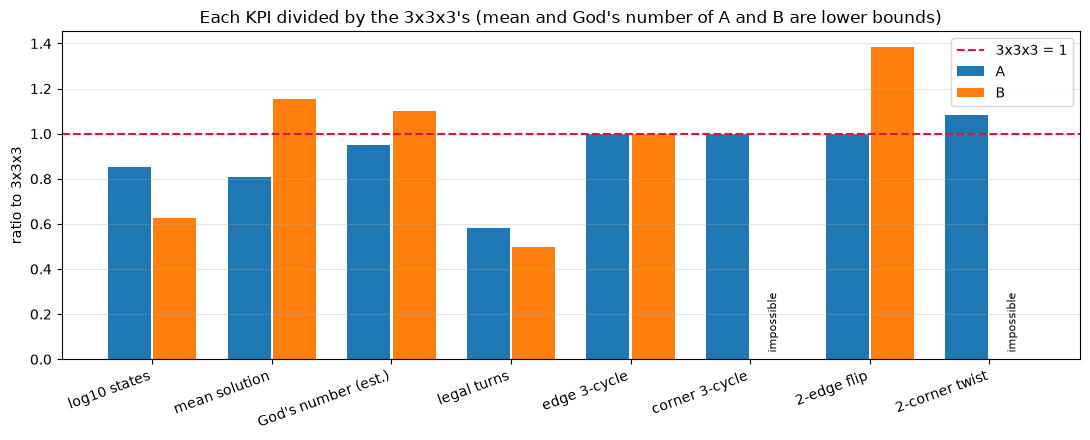

In [3]:
rows = {
    "log10 states": [np.log10(p["states"]) for p in (base, A, B)],
    "mean solution": [17.7, A["mean_distance"], B["mean_distance"]],
    "God's number (est.)": [20, max(A["gods_counting"] or 0, A["gods_lower"]), max(B["gods_counting"] or 0, B["gods_lower"])],
    "legal turns": [18, A["branching"], B["branching"]],
}
for k, label in KINDS:
    rows[label] = [base["algs"][k]["min_len"], A[k]["min_len"], B[k]["min_len"]]
rel = pd.DataFrame(rows, index=["3x3x3", "A", "B"]).T
fig, ax = plt.subplots(figsize=(11, 4.5))
ratio = rel[["A", "B"]].div(rel["3x3x3"], axis=0)
x = np.arange(len(ratio))
for i, (name, c) in enumerate([("A", "C0"), ("B", "C1")]):
    vals = ratio[name].values
    ax.bar(x + (i - .5) * .38, np.nan_to_num(vals), .36, color=c, label=name)
    for xi, v in zip(x, vals):
        if np.isnan(v):
            ax.text(xi + (i - .5) * .38, .03, "impossible", rotation=90, ha="center", va="bottom", fontsize=8)
ax.axhline(1, c="crimson", ls="--", label="3x3x3 = 1")
ax.set_xticks(x, ratio.index, rotation=20, ha="right"); ax.set_ylabel("ratio to 3x3x3"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Each KPI divided by the 3x3x3's (mean and God's number of A and B are lower bounds)")
plt.tight_layout()
rel.round(2)

## How fast each puzzle opens up

Positions at each distance from solved, as far as the table enumerates. The 3x3x3 grows about 13x
per move. The bandaged cubes grow more slowly, so the same number of positions sits deeper: that is
why a much smaller puzzle can still need as many moves.

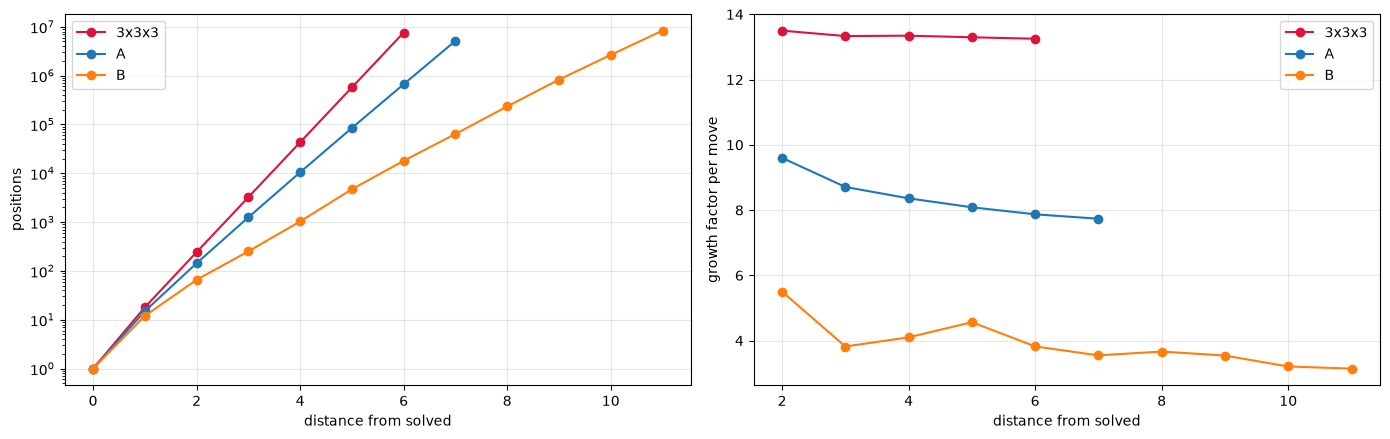

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for p, c in [(base, "crimson"), (A, "C0"), (B, "C1")]:
    ls = p["layer_sizes"]
    name = "3x3x3" if p is base else p["name"]
    axes[0].plot(range(len(ls)), ls, "o-", c=c, label=name)
    g = [ls[i + 1] / ls[i] for i in range(1, len(ls) - 1)]
    axes[1].plot(range(2, len(ls)), g, "o-", c=c, label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("distance from solved"); axes[0].set_ylabel("positions"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_xlabel("distance from solved"); axes[1].set_ylabel("growth factor per move"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout()

## The algorithms

The shortest algorithm found for each effect, replayed on the bandaged cube to check it is legal and
does exactly that. Dots mark the affected pieces.

,puzzle,effect,moves,algorithm,effect
0,A,edge 3-cycle,6,B U2 F B' R2 F',(UR UL DR)
1,A,corner 3-cycle,8,B L F' L' B' L F L',(URF UBR+ ULB-)
2,A,2-edge flip,13,B L F' L' B' U2 F U F U' F2 U2 F,UF* UL*
3,A,2-corner twist,13,B L F' L2 B D2 B' D2 L B' L2 F L2,ULB+ DBL-
4,B,edge 3-cycle,6,D B2 U D' R2 U',(FR BR BL)
5,B,corner 3-cycle,impossible,,
6,B,2-edge flip,18,D F B' L U D' B2 U' D L' F' B D' R' L B2 R L',UB* DB*
7,B,2-corner twist,impossible,,


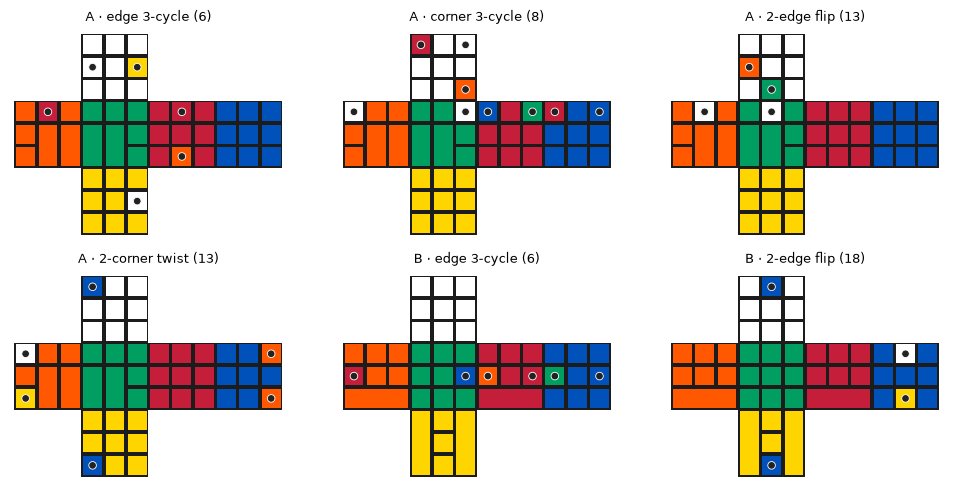

In [5]:
cubes, titles, marks, recs = [], [], [], []
for p in two:
    for k, label in KINDS:
        a = p[k]
        if not a["example"]:
            recs.append((p["name"], label, "impossible" if a["possible"] == 0 else "not found", "", ""))
            continue
        c = rubik.Cube(bandage=p["input"]).apply(a["example"])          # raises if a move is blocked
        e = rubik.analyze(a["example"], bandage=p["input"])
        assert c.effect()["description"] == e["description"]
        cubes.append(c); titles.append(f"{p['name']} · {label} ({a['min_len']})"); marks.append(e["affected"])
        recs.append((p["name"], label, a["min_len"], a["example"], e["description"]))
rubik.plot_cubes(cubes, titles=titles, highlights=marks, ncols=3)
pd.DataFrame(recs, columns=["puzzle", "effect", "moves", "algorithm", "effect"])

## Where they sit among 100 random bandaged cubes

Each grey dot is a random puzzle from the main study (hollow: lower bound).

,A,B
random puzzles with fewer states,70%,38%
random puzzles with a lower mean solution,30%,70%
random puzzles with fewer legal turns,74%,67%


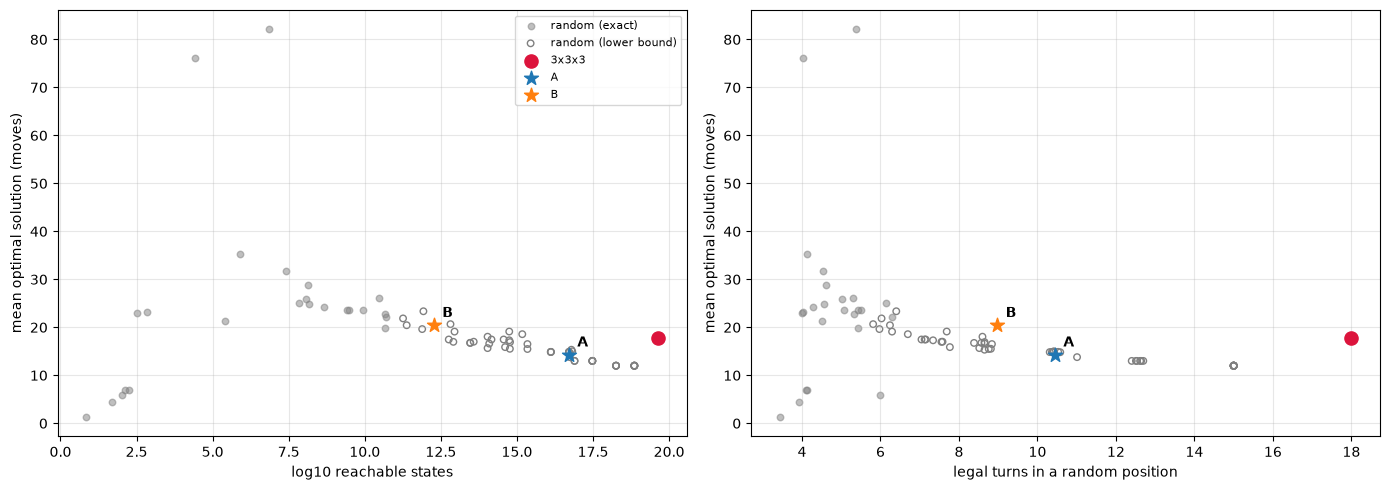

In [6]:
rs = [r for r in study if r["id"] != "333"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, xk, xl in [(axes[0], "states", "log10 reachable states"), (axes[1], "branching", "legal turns in a random position")]:
    xs = lambda r: np.log10(r["states"]) if xk == "states" else r[xk]
    ex = [r for r in rs if r["mean_distance_exact"]]
    lb = [r for r in rs if not r["mean_distance_exact"]]
    ax.scatter([xs(r) for r in ex], [r["mean_distance"] for r in ex], c="grey", alpha=.5, s=22, label="random (exact)")
    ax.scatter([xs(r) for r in lb], [r["mean_distance"] for r in lb], facecolors="none", edgecolors="grey", s=22, label="random (lower bound)")
    ax.scatter([xs(base)], [17.7], c="crimson", s=90, label="3x3x3", zorder=5)
    for p, c in [(A, "C0"), (B, "C1")]:
        ax.scatter([xs(p)], [p["mean_distance"]], c=c, s=110, marker="*", zorder=6, label=p["name"])
        ax.annotate(p["name"], (xs(p), p["mean_distance"]), xytext=(6, 6), textcoords="offset points", fontweight="bold")
    ax.set_xlabel(xl); ax.set_ylabel("mean optimal solution (moves)"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8); plt.tight_layout()

def pct(key, p, lower_is_easier=True):
    vals = np.array([r[key] for r in rs], dtype=float)
    return f"{(vals < p[key]).mean():.0%}"
pd.DataFrame({p["name"]: {"random puzzles with fewer states": pct("states", p),
                          "random puzzles with a lower mean solution": pct("mean_distance", p),
                          "random puzzles with fewer legal turns": pct("branching", p)} for p in two})

## Conclusions

**A: `F + FD | FL + FLD | L + LD`, a 3x3x3 with a sticky bottom-front-left.**

* About 5.1×10¹⁶ positions, roughly 850 times fewer than the 3x3x3.
* At the start only `D` is blocked (15 of 18 turns are legal), and a random position still has about 10.4 legal turns.
* Its algorithm toolkit is the 3x3x3's: edge 3-cycle in 6, corner 3-cycle in 8, 2-edge flip in 13 (all the same as the 3x3x3), and 2-corner twist in 13 (one more). Every one of these effects is possible on every free piece.
* Average optimal solution is at least 14.3 moves, and God's number is at least 15 (counting estimate ~19). These lower bounds don't settle whether it is shorter or longer than the 3x3x3's 17.7 / 20.
* **Verdict: about as hard as a 3x3x3.** A smaller state space, the same commutators, and the extra work is routing around the blocked bottom face.

**B: `LDB + LD + LDF | RDB + RD + RDF`, two 1x1x3 bars on the bottom edges.**

* About 1.9×10¹² positions, roughly 23 million times fewer than the 3x3x3.
* Yet the average optimal solution is **at least 20.4 moves**, provably longer than the 3x3x3's 17.7. God's number is **at least 21**, provably above the 3x3x3's 20.
* `F` and `B` are blocked at the start (12 of 18 legal), and about 9 turns are legal in a random position.
* Edge 3-cycles still take 6 moves, but a 2-edge flip needs 18 (3x3x3: 13).
* **No pure corner 3-cycle and no 2-corner twist exist at all.** This is exact, from the puzzle's group: corners can't be fixed with the usual isolated corner commutators. They have to be solved by a different method, together with the shape or the other pieces.
* **Verdict: harder than a 3x3x3 to solve optimally and to solve by hand.** Bandaging removed positions but made the remaining ones farther apart, and it took away the standard corner tools.

Both are lower bounds where marked: the true mean and God's number can only be higher.